# Plotter manual tests

## Test as a function first

In [26]:
from circle import Circle
from rectangle import Rectangle

from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle as MplRectangle
from matplotlib.patches import Circle as MplCircle

def plot2d(*shapes: Circle | Rectangle) -> tuple[plt.Figure, plt.Axes]:
    for shape in shapes:
        if not isinstance(shape, Circle | Rectangle):
            raise TypeError(f"Shape must be a Circle or Rectangle object, not {type(shape).__name__}")

    fig, axes = plt.subplots()

    for shape in shapes:
        if isinstance(shape, Rectangle):
            axes.add_patch(
                MplRectangle(
                    xy=(shape.x - (shape.width / 2), shape.y - (shape.height / 2)), # x, y in Shape objects represent the center. Subtract half of width and height to match bottom-left
                    width=shape.width,
                    height=shape.height,
                    facecolor="none",
                    edgecolor="black"
                    )
                )

        if isinstance(shape, Circle):
            axes.add_patch(
                MplCircle(
                    xy=(shape.x, shape.y),
                    radius=shape.radius,
                    facecolor="none",
                    edgecolor="blue"
                    )
                )

    # Equalize aspect ratio to prevent distorted shapes
    axes.autoscale_view(True)
    axes.axhline(0)
    axes.axvline(0)
    axes.set(aspect="equal")

    plt.show()    
    

### Call function with test values

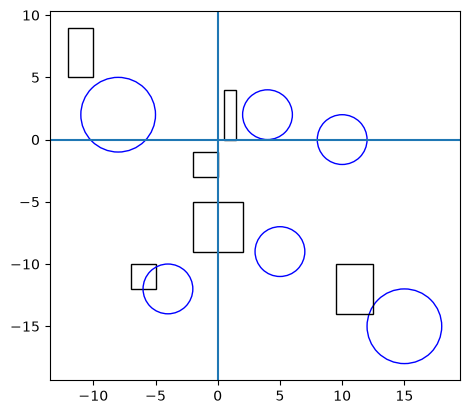

In [27]:
import random as rnd

shapes = []

for i in range(6):
    shapes.append(Rectangle(rnd.randint(1, 4), rnd.randint(1, 4), rnd.randint(-15, 15), rnd.randint(-15, 15)))
    shapes.append(Circle(rnd.randint(2, 4), rnd.randint(-15, 15), rnd.randint(-15, 15)))

plot2d(*shapes)

## Use the new class

C:\Users\linus\AppData\Local\Temp\ipykernel_20008\1853698931.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


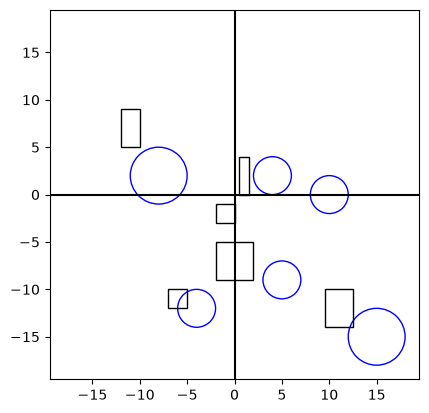

In [28]:
from shape2dplotter import Shape2DPlotter

fig, axes = Shape2DPlotter.plot2d(*shapes)
fig.show()

## Test abs max idea for getting max extent for a centered (0, 0) coordinate system

In [29]:
tup_1, tup_2 = (-20, 15), (-35, 24)

print(f"{abs(max(max(*tup_1, key=abs), max(*tup_2, key=abs))) = }") # 20 - Fail
print(f"{abs(max((*tup_1, *tup_2), key=abs)) = }") # 35 - Success but bad readability

abs(max(max(*tup_1, key=abs), max(*tup_2, key=abs))) = 20
abs(max((*tup_1, *tup_2), key=abs)) = 35


### Cleaner more readable version

In [30]:
x_limits, y_limits = (-20, 15), (-35, 24)

furthest_coordinate = max((*x_limits, *y_limits), key=abs)
print(f"{furthest_coordinate = }")

max_extent = abs(furthest_coordinate)
print(f"{max_extent = }")

furthest_coordinate = -35
max_extent = 35


## For-loop with unpacking test

In [31]:
test_tuple_1, test_tuple_2 = (-20, 15), (-35, 24)

for value in *test_tuple_1, *test_tuple_2:
    print(f"{value = }")

value = -20
value = 15
value = -35
value = 24



---

## Manual tests

### Test if patches is getting added and type validate fig, axes

type(fig) = <class 'matplotlib.figure.Figure'>
type(axes) = <class 'matplotlib.axes._axes.Axes'>
len(axes.patches) = 12


(True, True)

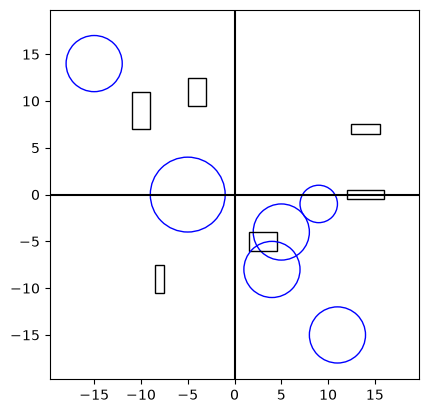

In [32]:
import matplotlib

shapes = []

for i in range(6):
    shapes.append(Rectangle(rnd.randint(1, 4), rnd.randint(1, 4), rnd.randint(-15, 15), rnd.randint(-15, 15)))
    shapes.append(Circle(rnd.randint(2, 4), rnd.randint(-15, 15), rnd.randint(-15, 15)))

fig, axes = Shape2DPlotter.plot2d(*shapes)

print(f"{type(fig) = }") # Expected: matplotlib.figure.Figure
print(f"{type(axes) = }") # Expected: matplotlib.axes.Axes

print(f"{len(axes.patches) = }") # Expected: 12

isinstance(fig, matplotlib.figure.Figure), isinstance(axes, matplotlib.axes.Axes) # Expected: True, True

### Validate patch types

#### Inspect types

In [33]:
print(f"{axes.patches[0] = }")
print(f"{axes.patches[1] = }")

axes.patches[0] = <matplotlib.patches.Rectangle object at 0x00000238C8105090>
axes.patches[1] = <matplotlib.patches.Circle object at 0x00000238C81051D0>


#### Test a loop to separate and count shapes

In [34]:
rectangles = []
circles = []

for shape in axes.patches:
    if isinstance(shape, matplotlib.patches.Rectangle):
        rectangles.append(shape)
        continue
    if isinstance(shape, matplotlib.patches.Circle):
        circles.append(shape)
        continue

print(f"{rectangles[0] = }")
print(f"{rectangles[1] = }")
print(f"{len(rectangles) = }")
print()
print(f"{circles[0] = }")
print(f"{circles[1] = }")
print(f"{len(circles) = }")

rectangles[0] = <matplotlib.patches.Rectangle object at 0x00000238C8105090>
rectangles[1] = <matplotlib.patches.Rectangle object at 0x00000238C8105310>
len(rectangles) = 6

circles[0] = <matplotlib.patches.Circle object at 0x00000238C81051D0>
circles[1] = <matplotlib.patches.Circle object at 0x00000238C8105450>
len(circles) = 6


#### Inspect how values are stored

In [35]:
print("Rectangle:")
print(f"{rectangles[0].xy = }")
print(f"{rectangles[0].get_width() = }")
print(f"{rectangles[0].get_height() = }")
print()
print("Circle:")
print(f"{circles[0].center = }") # Matplotlib's Circle patch uses center instead of xy
print(f"{circles[0].get_width() = }")
print(f"{circles[0].get_height() = }")

Rectangle:
rectangles[0].xy = (-5.0, 9.5)
rectangles[0].get_width() = 2
rectangles[0].get_height() = 3

Circle:
circles[0].center = (9, -1)
circles[0].get_width() = 4
circles[0].get_height() = 4


#### Validate shape values

In [36]:
rectangle_original_width = shapes[0].width
rectangle_original_height = shapes[0].height
rectangle_original_x, rectangle_original_y = shapes[0].x, shapes[0].y

circle_original_radius = shapes[1].radius
circle_original_x, circle_original_y = shapes[1].x, shapes[1].y

rectangle_patch_width = rectangles[0].get_width()
rectangle_patch_height = rectangles[0].get_height()
rectangle_patch_x, rectangle_patch_y = rectangles[0].get_center()

circle_patch_radius = circles[0].radius
circle_patch_x, circle_patch_y = circles[0].center

# Expected: True for all
print("Rectangle validations:")
print(f"width: {rectangle_original_width == rectangle_patch_width}")
print(f"height: {rectangle_original_height == rectangle_patch_height}")
print(f"x: {rectangle_original_x == rectangle_patch_x}")
print(f"y: {rectangle_original_y == rectangle_patch_y}")
print()
print("Circle validations:")
print(f"radius: {circle_original_radius == circle_patch_radius}")
print(f"x: {circle_original_x == circle_patch_x}")
print(f"y: {circle_original_y == circle_patch_y}")

Rectangle validations:
width: True
height: True
x: True
y: True

Circle validations:
radius: True
x: True
y: True


#### Test error handling

In [37]:
try:
    Shape2DPlotter.plot2d(5.95)
except TypeError as err:
    print(err)

try:
    Shape2DPlotter.plot2d(5)
except TypeError as err:
    print(err)

try:
    Shape2DPlotter.plot2d(True)
except TypeError as err:
    print(err)
try:
    Shape2DPlotter.plot2d("...")
except TypeError as err:
    print(err)

Shape must be a Circle or Rectangle object, not float
Shape must be a Circle or Rectangle object, not int
Shape must be a Circle or Rectangle object, not bool
Shape must be a Circle or Rectangle object, not str
